# Bài thực hành 8: Phân cụm K-Means

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu:
- `data/khach_hang.csv`: 210 khách hàng của một trung tâm thương mại, 3 cột `tuoi`, `thu_nhap` (triệu đồng/tháng), `diem_chi_tieu` (1 tới 100). **Không có cột nhãn.** Đề không phát kèm tệp này, nên tệp được dựng lại bằng `data/tao_khach_hang.py` (số liệu mô phỏng) theo đúng các con số đề cho: bảng `describe`, tâm, số khách và tuổi trung bình của năm cụm. Vì vậy vài con số lệch nhẹ so với tài liệu, ghi rõ trong từng nhận xét.
- `data/hai_vang_trang.csv`: dùng lại từ bài 4, 300 điểm, cột `x1`, `x2`, `nhan`.
- Ảnh `china.jpg` và `flower.jpg` có sẵn trong scikit-learn (`load_sample_image`), không cần tải.

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap08/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab08/`, ví dụ `python baitap08/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải hai tệp lên
import os
CAN_CO = ["data/khach_hang.csv", "data/hai_vang_trang.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca khach_hang.csv va hai_vang_trang.csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/khach_hang.csv chua? True
Co data/hai_vang_trang.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Năm màu cố định cho năm cụm, dùng chung cho mọi hình
MAU_CUM = ["#2a78d6", "#eb6834", "#1f9e89", "#7b5ea7", "#d1495b"]
DAU_CUM = ["o", "s", "^", "D", "v"]
MAU_TAM = "#1d1c1a"
MAU_CHU = "#52514e"
MAU_XAM = "#8d8b85"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})


def ve_cum(ax, X, nhan, tam=None, ten_tam=True):
    """Ve cac diem to mau theo cum (X la mang n x 2) va dau X o tam cum."""
    for k in np.unique(nhan):
        nhom = X[nhan == k]
        ax.scatter(nhom[:, 0], nhom[:, 1], s=16, c=MAU_CUM[k % 5], marker=DAU_CUM[k % 5],
                   edgecolor="white", linewidth=0.4, label=f"Cụm {k}")
    if tam is not None:
        ax.scatter(tam[:, 0], tam[:, 1], marker="X", s=180, c=MAU_TAM, edgecolor="white", linewidth=1.2)
        if ten_tam:
            for k, t in enumerate(tam):
                ax.annotate(f"Cụm {k}", t, xytext=(8, 6), textcoords="offset points", fontsize=9,
                            fontweight="bold")

## 1. Tự viết K-Means (`code/k1_tu_viet.py`)

1. Chọn K điểm làm tâm ban đầu. 2. **Gán**: mỗi điểm về cụm của tâm gần nhất. 3. **Dời tâm**: mỗi tâm dời về trung bình các điểm trong cụm. 4. Lặp lại 2 và 3 tới khi tâm không đổi.

$$\text{Inertia} = \sum_i \lVert x_i - \text{tâm của cụm chứa } x_i \rVert^2$$

In [3]:
import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


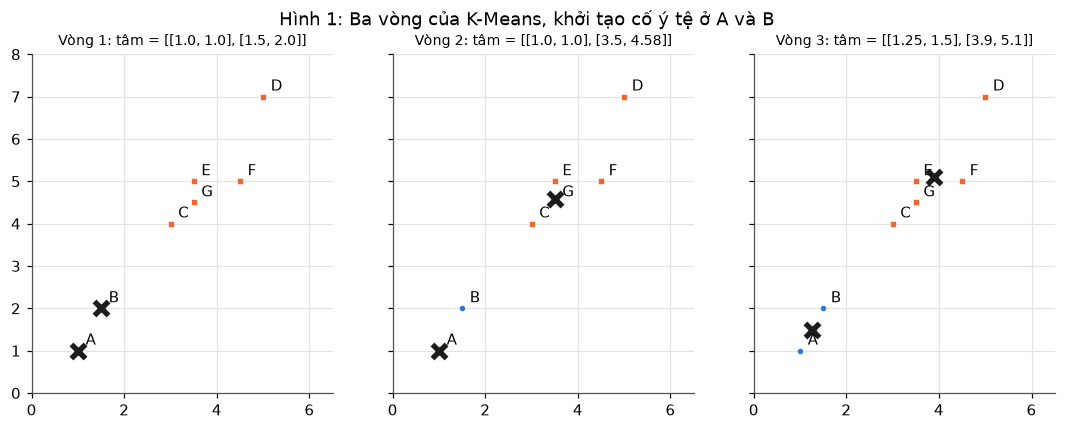

In [4]:
# Hình 1: ba vòng của K-Means trên bảy điểm, dấu X là tâm ở đầu mỗi vòng
tam_vong = P[[0, 1]].copy()
fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for vong, ax in enumerate(axs, start=1):
    nhan_vong = np.sqrt(((P[:, None, :] - tam_vong[None, :, :]) ** 2).sum(axis=2)).argmin(axis=1)
    ve_cum(ax, P, nhan_vong, tam_vong, ten_tam=False)
    for i, ten in enumerate(TEN):
        ax.annotate(ten, P[i], xytext=(5, 4), textcoords="offset points", fontsize=10)
    ax.set_title(f"Vòng {vong}: tâm = {np.round(tam_vong, 2).tolist()}", fontsize=9)
    ax.set_xlim(0, 6.5); ax.set_ylim(0, 8)
    tam_vong = np.array([P[nhan_vong == k].mean(axis=0) for k in range(2)])
fig.suptitle("Hình 1: Ba vòng của K-Means, khởi tạo cố ý tệ ở A và B"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số. Hai tâm ban đầu A và B nằm sát nhau, nên ở **vòng 1** chỉ A về cụm 1, sáu điểm còn lại đều gần B hơn. Dời tâm: tâm cụm 2 về trung bình sáu điểm B…G, tức (3.50, 4.58). Ở **vòng 2**, B giờ gần A (khoảng cách ≈ 1.1) hơn gần tâm mới (≈ 3.2), nên chuyển sang cụm 1. Dời tâm lần nữa được (1.25, 1.50) và (3.90, 5.10). Ở **vòng 3** không điểm nào đổi cụm, tâm không đổi, thuật toán dừng sau 3 vòng.

Inertia tự tính bằng **8.5250**, trùng với `KMeans(init=P[[0, 1]], n_init=1)` của scikit-learn, và tâm cũng trùng. Kiểm tra tay: cụm 1 góp 0.25² + 0.5² + 0.25² + 0.5² = 0.625, cụm 2 góp 7.9, cộng lại 8.525.

Dòng `X[:, None, :] - tam[None, :, :]` dùng broadcasting tạo mảng 7 × 2 × 2 (điểm × tâm × tọa độ); cộng bình phương theo trục cuối được bảng khoảng cách 7 × 2, `argmin(axis=1)` chọn tâm gần nhất cho mỗi điểm. Mỗi vòng, cả bước gán lẫn bước dời tâm đều không làm inertia tăng, nên thuật toán chắc chắn dừng; dù khởi tạo tệ, trên bảy điểm này nó vẫn tìm ra cách chia hợp lý (Hình 1).

## 2. Phân khúc khách hàng (`code/k2_khach_hang.py`)

In [5]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.4       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.9           22.0
50%     38.0      17.4           49.0
75%     45.0      28.6           76.8
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.1        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.5
3       8.0           19.0        40     44.9
4      30.2           81.4        40     32.6

Inertia: 22.98

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


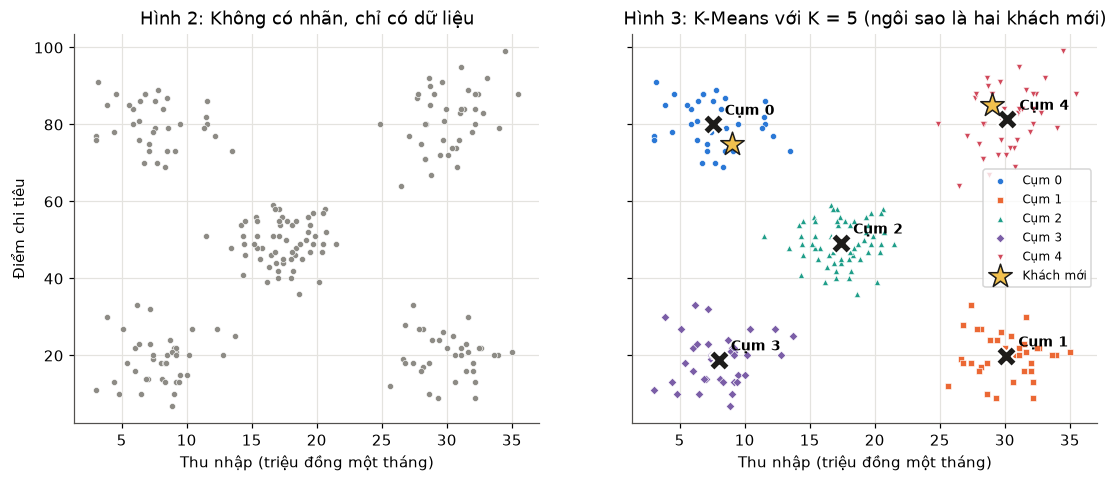

In [6]:
# Hình 2 và Hình 3: dữ liệu chưa có nhãn, và năm cụm K-Means tìm ra (số cụm đúng như máy in ra)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
axs[0].scatter(df["thu_nhap"], df["diem_chi_tieu"], s=16, c=MAU_XAM, edgecolor="white", linewidth=0.4)
axs[0].set_title("Hình 2: Không có nhãn, chỉ có dữ liệu")
ve_cum(axs[1], X.to_numpy(), km.labels_, tam[["thu_nhap", "diem_chi_tieu"]].to_numpy())
axs[1].scatter(moi["thu_nhap"], moi["diem_chi_tieu"], marker="*", s=260, c="#f2c14e", edgecolor=MAU_TAM,
               linewidth=1, label="Khách mới")
axs[1].set_title("Hình 3: K-Means với K = 5 (ngôi sao là hai khách mới)")
axs[1].legend(fontsize=8, loc="center right")
for ax in axs:
    ax.set_xlabel("Thu nhập (triệu đồng một tháng)")
axs[0].set_ylabel("Điểm chi tiêu"); plt.show()

**Nhận xét.** Kích thước (210, 3), không có cột nhãn. Vì tệp dữ liệu được dựng lại (xem đầu notebook), bảng `describe` khớp tài liệu ở hầu hết các ô, chỉ lệch ở hàng thập phân của vài ô: độ lệch chuẩn của tuổi 10.4 (đề 10.3), trung vị và phân vị 75% của tuổi 38 và 45 (đề 39 và 46), phân vị 25% của thu nhập 8.9 (đề 8.8), phân vị 75% của điểm chi tiêu 76.8 (đề 77). Hai con số quan trọng nhất trùng: độ lệch chuẩn của thu nhập **9.8** và của điểm chi tiêu **26.8**. Hai thang đo khác nhau gần 3 lần, nên phải chuẩn hoá trước khi phân cụm.

Tâm cụm (đã đổi về đơn vị gốc bằng `sc.inverse_transform`), số khách và tuổi trung bình khớp tài liệu, kể cả **số thứ tự cụm**: cụm 0 (7.5 triệu, 80.1 điểm, 35 khách, 24.9 tuổi), cụm 1 (30.1; 20.0; 35; 42.9), cụm 2 (17.4; 49.3; 60; 40.5), cụm 3 (8.0; 19.0; 40; 44.9), cụm 4 (30.2; 81.4; 40; 32.6). Lệch tối đa 0.1 so với đề (80.2, 18.9, 81.5, 40.4). Inertia **22.98**, đề 23.02: lệch 0.04 do dữ liệu dựng lại không trùng từng khách.

Đọc năm cụm như Bảng 3 của đề: cụm 0 thu nhập thấp nhưng chi nhiều và trẻ nhất (24.9 tuổi), hợp với trả góp, tích điểm; cụm 1 thu nhập cao mà chi ít, cần tìm hiểu vì sao; cụm 2 vừa phải và đông nhất (60 khách); cụm 3 thu nhập thấp, chi ít, lớn tuổi nhất (44.9); cụm 4 thu nhập cao, chi nhiều, khách thân thiết. Hình 3 cho thấy năm cụm tách bạch, mỗi dấu X nằm giữa một đám điểm.

Hai khách mới, chuẩn hoá bằng **đúng bộ `sc` cũ** rồi `km.predict`: khách 29 triệu, chi 85 vào **cụm 4** (thu nhập cao, chi nhiều); khách 9 triệu, chi 75 vào **cụm 0** (thu nhập thấp, chi nhiều), như tài liệu. Hai ngôi sao trên Hình 3 nằm ngay trong hai đám đó.

## 3. Chọn số cụm K (`code/k3_chon_k.py`)

**Khuỷu tay:** vẽ inertia theo K, chọn chỗ đường gập. **Silhouette:** với mỗi điểm, *a* là khoảng cách trung bình tới các điểm cùng cụm, *b* là khoảng cách trung bình tới các điểm của cụm gần nhất khác,

$$s = \frac{b - a}{\max(a, b)},$$

lấy trung bình *s* của mọi điểm và chọn K cho giá trị lớn nhất.

In [7]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K   inertia   giam so voi K-1   silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d}   {km.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km.inertia_

 K   inertia   giam so voi K-1   silhouette
  1     420.0                               
  2     252.4             167.6        0.427
  3     153.6              98.8        0.521
  4      75.1              78.5        0.624
  5      23.0              52.2        0.723


  6      20.1               2.8        0.661
  7      18.2               2.0        0.547
  8      16.3               1.9        0.491
  9      15.1               1.2        0.497
 10      13.4               1.7        0.357


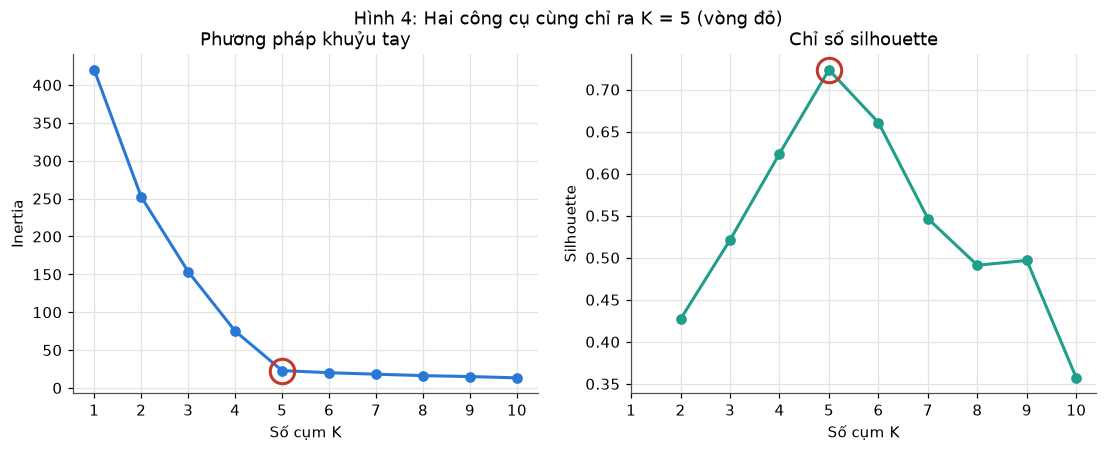

In [8]:
# Hình 4: inertia và silhouette theo K
cac_k = list(range(1, 11))
ds_ine, ds_sil = [], []
for k in cac_k:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    ds_ine.append(m.inertia_)
    ds_sil.append(silhouette_score(Xs, m.labels_) if k > 1 else np.nan)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(cac_k, ds_ine, "o-", color=MAU_CUM[0])
axs[0].plot(5, ds_ine[4], "o", ms=16, mfc="none", mec="#c0392b", mew=2)
axs[0].set_title("Phương pháp khuỷu tay"); axs[0].set_ylabel("Inertia")
axs[1].plot(cac_k[1:], ds_sil[1:], "o-", color=MAU_CUM[2])
axs[1].plot(5, ds_sil[4], "o", ms=16, mfc="none", mec="#c0392b", mew=2)
axs[1].set_title("Chỉ số silhouette"); axs[1].set_ylabel("Silhouette")
for ax in axs:
    ax.set_xlabel("Số cụm K"); ax.set_xticks(cac_k)
fig.suptitle("Hình 4: Hai công cụ cùng chỉ ra K = 5 (vòng đỏ)"); plt.show()

**Nhận xét.** Kết luận trùng tài liệu: **cả hai công cụ cùng chọn K = 5.**

- Khuỷu tay: inertia giảm mạnh tới K = 5 (từ K = 4 xuống K = 5 còn giảm **52.2**, đề 50.7), rồi từ K = 5 lên K = 6 chỉ giảm **2.8** (đề 2.1), và từ đó mỗi cụm thêm chỉ giảm 1.2 tới 2.0. Đường gập rõ ở K = 5 (Hình 4 trái).
- Silhouette cao nhất ở K = 5, bằng **0.723**, đúng như đề. K = 4 và K = 6 được 0.624 và 0.661 (đề 0.626 và 0.651).

Các ô khác lệch nhẹ vì dữ liệu dựng lại: inertia K = 2, 3, 4 là 252.4, 153.6, 75.1 (đề 250.4, 152.5, 73.8); với K ≥ 6 inertia của tôi thấp hơn đề khoảng 1 và silhouette ở K = 8, 9, 10 là 0.491, 0.497, 0.357 (đề 0.454, 0.471, 0.425). Ở đó K-Means đang cắt vụn các nhóm thật, nên con số nhạy với vị trí từng khách; hình dạng hai đường vẫn y như Hình 4 của đề. Inertia K = 1 bằng đúng 420.0 = 2 cột × 210 khách, vì sau chuẩn hoá mỗi cột có phương sai 1.

Không chọn K theo inertia nhỏ nhất: inertia luôn giảm khi K tăng (K = 10 chỉ còn 13.4) và bằng 0 khi mỗi khách là một cụm. Silhouette thì phạt việc cắt một nhóm thật thành hai: khi cắt, *b* (khoảng cách tới cụm gần nhất khác) của các điểm sát vết cắt tụt mạnh, nên *s* giảm.

## 4. Ba cái bẫy của K-Means (`code/k4_ba_cai_bay.py`)

In [9]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000        # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
      f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  7.2,  45.7)
  ( 13.7,  54.0)
  ( 18.3,  49.1)
  ( 28.3,  53.1)
  ( 32.0,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [73.2, 73.4, 74.4, 74.9, 84.2, 85.7, 85.8, 117.3, 119.7, 120.0]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


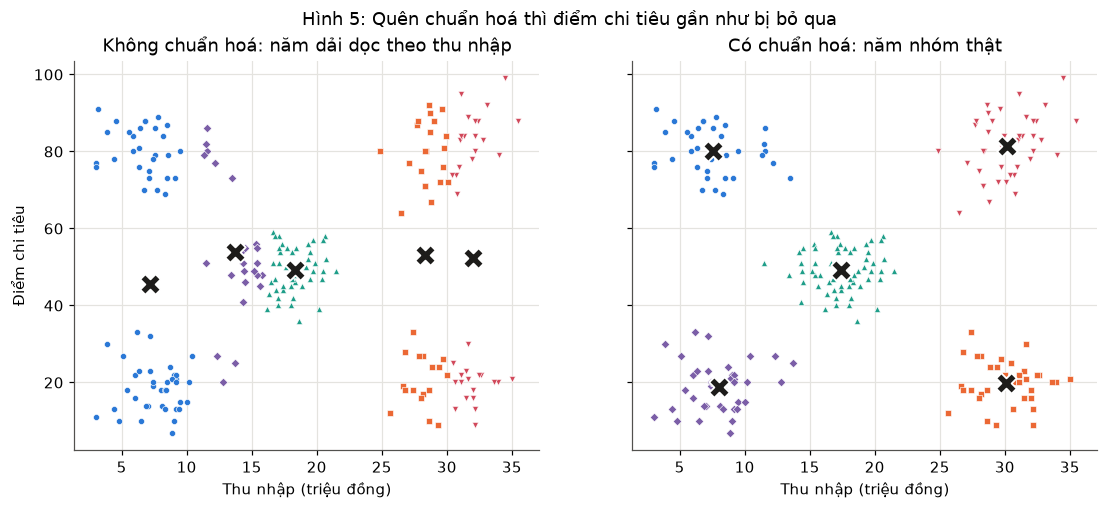

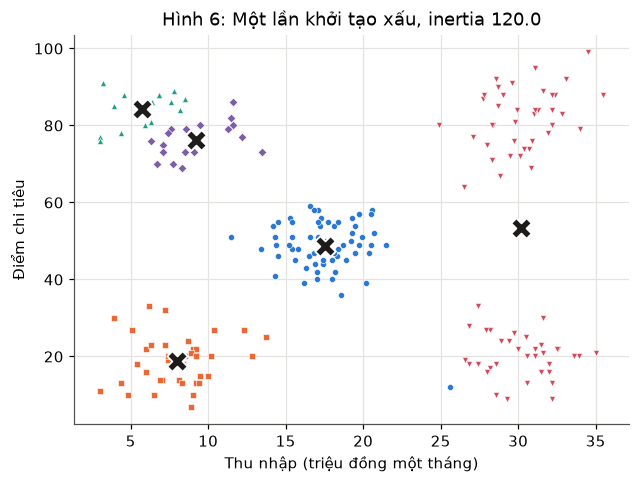

Kich thuoc cac cum cua lan te nhat: [61, 40, 17, 18, 74]
Tam (don vi goc): [[17.5, 48.7], [8.0, 19.0], [5.8, 84.3], [9.2, 76.2], [30.2, 53.3]]


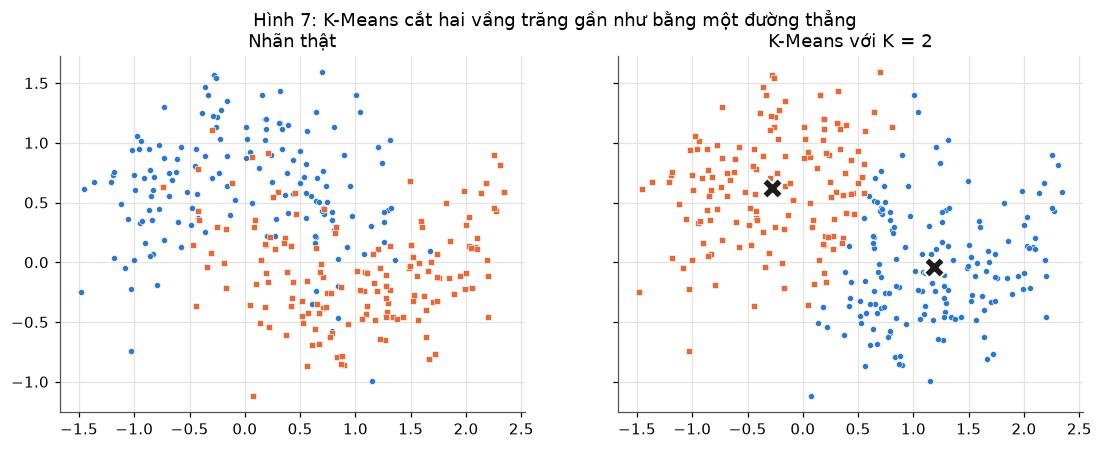

In [10]:
# Hình 5: không chuẩn hoá (thu nhập tính bằng nghìn đồng) và có chuẩn hoá
X_np = X.to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
ve_cum(axs[0], X_np, km_tho.labels_, tam_tho, ten_tam=False)
axs[0].set_title("Không chuẩn hoá: năm dải dọc theo thu nhập")
tam_tot = StandardScaler().fit(X).inverse_transform(tot.cluster_centers_)
ve_cum(axs[1], X_np, tot.labels_, tam_tot, ten_tam=False)
axs[1].set_title("Có chuẩn hoá: năm nhóm thật")
for ax in axs:
    ax.set_xlabel("Thu nhập (triệu đồng)")
axs[0].set_ylabel("Điểm chi tiêu")
fig.suptitle("Hình 5: Quên chuẩn hoá thì điểm chi tiêu gần như bị bỏ qua"); plt.show()

# Hình 6: lần khởi tạo ngẫu nhiên tệ nhất trong 20 lần
cac_lan = [KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs) for rs in range(20)]
te = max(cac_lan, key=lambda m: m.inertia_)
sc_tam = StandardScaler().fit(X)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ve_cum(ax, X_np, te.labels_, sc_tam.inverse_transform(te.cluster_centers_), ten_tam=False)
ax.set_xlabel("Thu nhập (triệu đồng một tháng)"); ax.set_ylabel("Điểm chi tiêu")
ax.set_title(f"Hình 6: Một lần khởi tạo xấu, inertia {te.inertia_:.1f}"); plt.show()
print("Kich thuoc cac cum cua lan te nhat:", np.bincount(te.labels_).tolist())
print("Tam (don vi goc):", np.round(sc_tam.inverse_transform(te.cluster_centers_), 1).tolist())

# Hình 7: hai vầng trăng, nhãn thật và hai cụm K-Means
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
ve_cum(axs[0], tr[["x1", "x2"]].to_numpy(), tr["nhan"].to_numpy(), ten_tam=False)
axs[0].set_title("Nhãn thật")
ve_cum(axs[1], tr[["x1", "x2"]].to_numpy(), nhan, km_tr.cluster_centers_, ten_tam=False)
axs[1].set_title("K-Means với K = 2")
fig.suptitle("Hình 7: K-Means cắt hai vầng trăng gần như bằng một đường thẳng"); plt.show()

**Nhận xét.**

**Bẫy 1, quên chuẩn hoá.** Khi thu nhập ghi bằng nghìn đồng (3 000 tới 35 500) mà điểm chi tiêu chỉ từ 7 tới 99, khoảng cách gần như chỉ là chênh lệch thu nhập. Năm tâm có điểm chi tiêu gần nhau, từ **45.7 tới 54.0** (đề 41.9 tới 52.9), và chỉ khác nhau ở thu nhập: 7.2, 13.7, 18.3, 28.3, 32.0 (đề 6.1, 9.6, 17.4, 27.8, 31.9). Hình 5 trái cho thấy năm dải dọc: hai nhóm thu nhập thấp (chi nhiều và chi ít) bị gộp làm một, tâm rơi vào khoảng trống giữa chúng ở điểm chi tiêu 45.7, còn hai nhóm thu nhập cao bị cắt dọc ở khoảng 30 triệu. Vị trí tâm khác đề vài triệu đồng vì dữ liệu dựng lại, nhưng hiện tượng y hệt. Có chuẩn hoá (Hình 5 phải) thì năm nhóm hiện ra đúng.

**Bẫy 2, khởi tạo xấu.** Trong 20 lần `init="random", n_init=1`, đúng **10 lần đạt 23.0** và 10 lần dừng ở cách chia kém hơn: 73.2, 73.4, 74.4, 74.9, 84.2, 85.7, 85.8, 117.3, 119.7, **120.0** (đề: cũng 10 lần, từ 72.4 tới 118.2). Mỗi mức inertia lặp lại (73.x, 84.2, 85.x, 117 tới 120) ứng với một kiểu gộp hai nhóm và cắt đôi một nhóm khác. Lần tệ nhất (Hình 6, inertia 120.0) gộp hai nhóm thu nhập cao thành một cụm 74 khách với tâm (30.2, 53.3) nằm giữa khoảng trống, và cắt nhóm thu nhập thấp chi nhiều làm hai cụm 17 và 18 khách. Đề vẽ một lần xấu khác (gộp hai nhóm thu nhập thấp, cắt nhóm thu nhập cao chi nhiều), cùng một kiểu lỗi. K-Means chỉ dừng khi không bước nào cải thiện được, tức một cực tiểu cục bộ. `n_init=10` chạy 10 lần và giữ lần tốt nhất nên được **23.0**.

**Bẫy 3, cụm không tròn.** Trên hai vầng trăng, tỷ lệ khớp nhãn thật **0.7500**, khớp đề (dữ liệu chép nguyên từ bài 4). Mỗi điểm về tâm gần nhất nên ranh giới hai cụm là đường trung trực của hai tâm, một đường thẳng (Hình 7 phải); phần đầu của mỗi vầng trăng chìa sang nửa bên kia bị gán nhầm. Tỷ lệ khớp lấy `max(khop, 1 - khop)` vì số thứ tự cụm không có nghĩa: ở Hình 7, cụm 0 của K-Means lại ứng với nhãn 1.

## 5. Nén màu ảnh (`code/k5_nen_anh.py`)

In [11]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg")        # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0           # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print(" K   so bit moi diem   nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d}        {bit}            {24 / bit:4.1f} lan"
          f"      {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

 K   so bit moi diem   nho hon   sai lech trung binh
  4        2            12.0 lan      17.41 muc sang


 16        4             6.0 lan       7.97 muc sang
 64        6             4.0 lan       4.54 muc sang


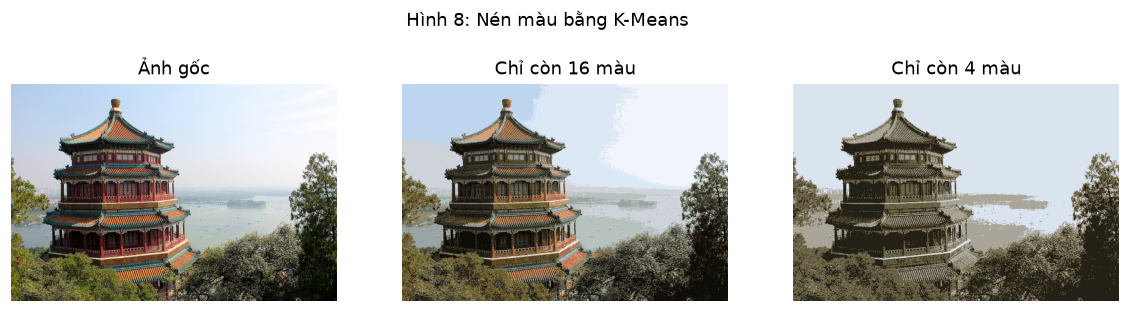

In [12]:
# Hình 8: ảnh gốc, ảnh 16 màu và ảnh 4 màu
anh_k = {}
for k in [16, 4]:
    m = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    anh_k[k] = m.cluster_centers_[m.predict(diem)].reshape(cao, rong, 3)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (ten, a) in zip(axs, [("Ảnh gốc", anh), ("Chỉ còn 16 màu", anh_k[16]), ("Chỉ còn 4 màu", anh_k[4])]):
    ax.imshow(a); ax.set_title(ten); ax.axis("off")
fig.suptitle("Hình 8: Nén màu bằng K-Means"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số: ảnh 427 × 640 có **273 280** điểm ảnh, dùng **96 615** màu khác nhau.

| K | bit mỗi điểm | nhỏ hơn | sai lệch trung bình |
|---|---|---|---|
| 4 | 2 | 12.0 lần | 17.41 mức sáng |
| 16 | 4 | 6.0 lần | 7.97 mức sáng |
| 64 | 6 | 4.0 lần | 4.54 mức sáng |

Mỗi điểm ảnh là một điểm (đỏ, xanh lá, xanh dương) trong không gian ba chiều; K-Means tìm K màu đại diện (tâm cụm) rồi tô mỗi điểm bằng màu tâm của nó. Ảnh gốc cần 24 bit một điểm; ảnh K màu chỉ cần lưu số thứ tự màu, ⌈log₂K⌉ bit, cộng một bảng K màu rất nhỏ. Với 16 màu, nhỏ hơn 6 lần mà mỗi kênh chỉ lệch trung bình 7.97 trên 255: ở Hình 8 ảnh 16 màu nhìn gần như ảnh gốc, chỉ bầu trời hơi thành từng mảng. Với 4 màu thì nhỏ hơn 12 lần nhưng lệch 17.41: bầu trời và cây cối loang rõ, và mái đỏ mất hẳn màu, cả ảnh chỉ còn các tông nâu xám, vì bốn tâm cụm phải dành cho những màu chiếm nhiều điểm ảnh nhất (trời, nước, cây tối). Đi từ 16 lên 64 màu, sai lệch chỉ giảm thêm 3.4 mức, cũng là kiểu "khuỷu tay" như mục 3.

Học trên 5 000 điểm rút ngẫu nhiên (chưa tới 2% số điểm) rồi `predict` cho cả 273 280 điểm là đủ, vì 5 000 điểm đã đại diện cho phân bố màu của ảnh.

---
# Bài tập

Mã của từng bài nằm trong `baitap08/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tự tính silhouette
Viết `silhouette_mot_diem(X, nhan, i)` tính *a*, *b*, *s* chỉ bằng numpy; chạy cho mọi khách với K = 5, lấy trung bình, so với `silhouette_score`. Khách nào có *s* nhỏ nhất? Khách đó nằm ở đâu trên Hình 3?

In [13]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
nhan = km.labels_


def silhouette_mot_diem(X, nhan, i):
    """Tra ve (a, b, s) cua diem thu i."""
    kc = np.sqrt(((X - X[i]) ** 2).sum(axis=1))      # khoảng cách từ i tới mọi điểm
    cung = (nhan == nhan[i])
    cung[i] = False                                  # không tính khoảng cách tới chính nó
    if cung.sum() == 0:                              # cụm chỉ có một điểm: quy ước s = 0
        return 0.0, 0.0, 0.0
    a = kc[cung].mean()
    # b: khoảng cách trung bình tới cụm khác gần nhất
    b = min(kc[nhan == k].mean() for k in np.unique(nhan) if k != nhan[i])
    s = (b - a) / max(a, b)
    return a, b, s


ket = np.array([silhouette_mot_diem(Xs, nhan, i) for i in range(len(Xs))])
s = ket[:, 2]
print(f"Silhouette tu tinh  : {s.mean():.6f}")
print(f"silhouette_score    : {silhouette_score(Xs, nhan):.6f}")
print(f"Chenh lech tuyet doi: {abs(s.mean() - silhouette_score(Xs, nhan)):.2e}")
print()

# Trung bình s theo từng cụm, kèm tâm cụm theo đơn vị gốc
tam = sc.inverse_transform(km.cluster_centers_)
print("Cum   tam (thu nhap, chi tieu)   so khach   s trung binh   s nho nhat")
for k in range(5):
    sk = s[nhan == k]
    print(f"  {k}   ({tam[k, 0]:5.1f}, {tam[k, 1]:5.1f})"
          f"            {len(sk):3d}       {sk.mean():.3f}        {sk.min():6.3f}")
print()

# Năm khách có s nhỏ nhất
print("Nam khach co s nho nhat:")
print("  dong   thu nhap   chi tieu   cum       a       b        s   cum gan nhat")
for i in np.argsort(s)[:5]:
    a, b, si = ket[i]
    # cụm khác gần nhất là cụm cho ra b
    gan = min((k for k in range(5) if k != nhan[i]),
              key=lambda k: np.sqrt(((Xs[nhan == k] - Xs[i]) ** 2).sum(axis=1)).mean())
    print(f"  {i:4d}   {X.iloc[i, 0]:8.1f}   {X.iloc[i, 1]:8d}   {nhan[i]:3d}"
          f"   {a:5.3f}   {b:5.3f}   {si:6.3f}   {gan:5d}")
print()
print("So khach co s am:", int((s < 0).sum()))

Silhouette tu tinh  : 0.723440
silhouette_score    : 0.723440
Chenh lech tuyet doi: 1.11e-16

Cum   tam (thu nhap, chi tieu)   so khach   s trung binh   s nho nhat
  0   (  7.5,  80.1)             35       0.702         0.274
  1   ( 30.1,  20.0)             35       0.758         0.489
  2   ( 17.4,  49.3)             60       0.717         0.452
  3   (  8.0,  19.0)             40       0.719         0.325
  4   ( 30.2,  81.5)             40       0.726         0.273

Nam khach co s nho nhat:
  dong   thu nhap   chi tieu   cum       a       b        s   cum gan nhat
    85       26.5         64     4   0.802   1.103    0.273       2
   208       13.5         73     0   0.725   0.998    0.274       2
   127       13.7         25     3   0.681   1.009    0.325       2
    44       12.3         27     3   0.598   1.009    0.407       2
   132       11.5         51     2   0.654   1.192    0.452       0

So khach co s am: 0


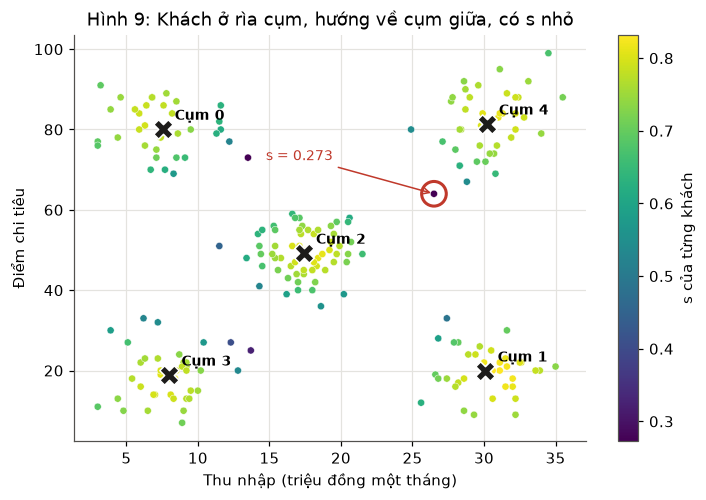

In [14]:
# Hình 9: silhouette của từng khách, khách s nhỏ nhất được khoanh đỏ
fig, ax = plt.subplots(figsize=(7.5, 4.8))
diem_s = ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=s, cmap="viridis", s=22, edgecolor="white", linewidth=0.3)
ax.scatter(tam[:, 0], tam[:, 1], marker="X", s=160, c=MAU_TAM, edgecolor="white")
for k, t in enumerate(tam):
    ax.annotate(f"Cụm {k}", t, xytext=(8, 6), textcoords="offset points", fontsize=9, fontweight="bold")
i_min = int(np.argmin(s))
ax.scatter(X.iloc[i_min, 0], X.iloc[i_min, 1], s=260, facecolor="none", edgecolor="#c0392b", linewidth=2)
ax.annotate(f"s = {s[i_min]:.3f}", (X.iloc[i_min, 0], X.iloc[i_min, 1]), xytext=(-110, 22),
            textcoords="offset points", color="#c0392b", fontsize=9,
            arrowprops=dict(arrowstyle="->", color="#c0392b"))
fig.colorbar(diem_s, ax=ax, label="s của từng khách")
ax.set_xlabel("Thu nhập (triệu đồng một tháng)"); ax.set_ylabel("Điểm chi tiêu")
ax.set_title("Hình 9: Khách ở rìa cụm, hướng về cụm giữa, có s nhỏ"); plt.show()

**Nhận xét.** Hàm tự viết cho silhouette trung bình **0.723440**, trùng `silhouette_score` tới sai số làm tròn của máy (1.1 × 10⁻¹⁶), và bằng 0.723 ở bảng chọn K. Ba chi tiết phải đúng định nghĩa thì mới trùng: *a* tính trên các điểm cùng cụm **trừ chính điểm i** (chia cho n − 1, không phải n); *b* là trung bình tới **từng** cụm khác rồi lấy cụm nhỏ nhất, không phải tới tâm cụm gần nhất; và khoảng cách đo trên dữ liệu **đã chuẩn hoá**, cùng thang mà K-Means đã dùng.

**Khách có s nhỏ nhất** là khách dòng 85: thu nhập 26.5 triệu, điểm chi tiêu 64, thuộc **cụm 4** (thu nhập cao, chi nhiều), với a = 0.802, b = 1.103, **s = 0.273**. Trên Hình 3, khách này nằm ở **rìa dưới bên trái của cụm 4**, lọt hẳn ra ngoài đám điểm, ở khoảng trống giữa cụm 4 và cụm 2 (cụm giữa). Hình 9 khoanh đỏ đúng khách đó. Khách đứng thứ hai (dòng 208, 13.5 triệu, chi 73, s = 0.274) ở tình huống đối xứng: rìa phải của cụm 0, cũng nhìn về cụm 2. Bốn trong năm khách có s nhỏ nhất có cụm gần nhất khác là **cụm 2**, khách thứ năm thuộc chính cụm 2: cụm 2 nằm giữa bốn cụm kia nên mọi ranh giới đều đi qua nó.

Cách đọc s: *a* nhỏ nghĩa là gần bạn cùng cụm, *b* lớn nghĩa là xa cụm khác. s gần 1 là điểm nằm sâu trong cụm của mình; s gần 0 là điểm nằm ở ranh giới hai cụm; s âm là điểm có lẽ bị xếp nhầm cụm. Ở đây **không khách nào có s âm** và s nhỏ nhất vẫn dương rõ (0.27), nghĩa là không ai bị xếp nhầm, chỉ có vài khách ở rìa. Trung bình theo cụm từ 0.702 (cụm 0, có một nhánh khách thu nhập 11 tới 13 triệu chìa về phía cụm giữa) tới 0.758 (cụm 1, đám điểm gọn nhất). Silhouette trung bình là bình quân của các mức này nên chỉ cần một vài khách rìa là kéo con số xuống.

## Bài tập 2: Thêm cột tuổi
Phân cụm trên cả ba cột tuổi, thu nhập, điểm chi tiêu (có chuẩn hoá); chọn lại K bằng silhouette với K từ 2 tới 10. K tốt nhất có còn là 5? Tâm cụm thay đổi thế nào so với mục 2?

In [15]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
COT = ["tuoi", "thu_nhap", "diem_chi_tieu"]
sc = StandardScaler().fit(df[COT])
Xs = sc.transform(df[COT])

print(" K   inertia   silhouette")
diem = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    diem[k] = silhouette_score(Xs, km.labels_)
    print(f" {k:2d}   {km.inertia_:7.1f}   {diem[k]:.3f}")
k_tot = max(diem, key=diem.get)
print(f"K tot nhat theo silhouette: {k_tot}")
print()


def in_tam(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=COT)
    tam["so_khach"] = np.bincount(km.labels_)
    # Xếp theo thu nhập rồi chi tiêu cho dễ so với mục 3
    print(f"Tam cum voi K = {k}, ba cot, don vi goc:")
    print(tam.sort_values(["thu_nhap", "diem_chi_tieu"]).round(1).to_string())
    print()
    return km


km_tot = in_tam(k_tot)
if k_tot != 5:
    in_tam(5)

# So với cách chia của mục 3 (chỉ hai cột)
X2 = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
nhan_2 = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(X2)
print("Bang cheo: hang la cum muc 3 (hai cot), cot la cum khi them tuoi")
print(pd.crosstab(nhan_2, km_tot.labels_, rownames=["hai_cot"], colnames=["ba_cot"]))

 K   inertia   silhouette
  2     366.3   0.390
  3     258.5   0.435
  4     174.2   0.481
  5     123.5   0.511


  6     100.5   0.522
  7      83.3   0.515
  8      69.7   0.507
  9      59.9   0.478


 10      54.0   0.433
K tot nhat theo silhouette: 6

Tam cum voi K = 6, ba cot, don vi goc:
   tuoi  thu_nhap  diem_chi_tieu  so_khach
4  52.0       7.8           19.2        22
3  35.8       8.8           19.5        19
2  24.2       9.2           75.0        42
5  43.4      17.4           49.5        52
1  42.9      30.1           20.0        35
0  32.6      30.2           81.4        40



Tam cum voi K = 5, ba cot, don vi goc:
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  45.3       7.9           18.8        39
4  24.2       9.2           75.0        42
3  42.8      17.3           48.8        54
2  42.9      30.1           20.0        35
1  32.6      30.2           81.4        40



Bang cheo: hang la cum muc 3 (hai cot), cot la cum khi them tuoi
ba_cot    0   1   2   3   4   5
hai_cot                        
0         0   0  35   0   0   0
1         0  35   0   0   0   0
2         0   0   7   1   0  52
3         0   0   0  18  22   0
4        40   0   0   0   0   0


**Nhận xét.** Lưu ý trước: cột tuổi trong tệp dựng lại chỉ được khớp theo tuổi trung bình từng cụm và bảng `describe` của đề, độ phân tán tuổi trong mỗi cụm là tôi chọn. Kết quả bài này phụ thuộc vào điều đó nhiều hơn các bài khác.

**K tốt nhất không còn là 5 mà là 6**, nhưng thắng sát nút: silhouette 0.522 ở K = 6 so với 0.511 ở K = 5 và 0.515 ở K = 7. Toàn bộ đường silhouette tụt từ khoảng 0.72 xuống khoảng 0.5, và không còn một đỉnh rõ. Lý do: tuổi không chia thành những nhóm tách bạch, nó trải đều trong mỗi nhóm. Thêm một cột có độ lệch chuẩn bằng 1 sau chuẩn hoá, gần như không mang cấu trúc cụm, làm mọi khoảng cách trong cụm (*a*) lớn lên, nên mọi *s* giảm.

**Tâm cụm thay đổi thế nào.** Hai nhóm thu nhập cao gần như không đổi: (42.9 tuổi; 30.1; 20.0; 35 khách) và (32.6; 30.2; 81.4; 40 khách), trùng hệt cụm 1 và cụm 4 ở mục 2. Thay đổi nằm ở ba nhóm còn lại:
- Với K = 6, nhóm **thu nhập thấp, chi ít** (cụm 3 ở mục 2, 40 khách) bị **tách đôi theo tuổi**: 22 khách quanh 52 tuổi và 19 khách quanh 36 tuổi. Đây là cụm thứ sáu.
- Nhóm **thu nhập thấp, chi nhiều, trẻ** (24.2 tuổi) tăng từ 35 lên 42 khách, vì 7 khách **trẻ nhất** của nhóm giữa (18 tới 26 tuổi) được kéo sang. Nhóm giữa còn 52 khách.
- Với K = 5 trên ba cột (in thêm ở trên), cũng đúng 7 khách đó chuyển sang nhóm trẻ chi nhiều, một khách nhóm thu nhập thấp chi ít chuyển vào nhóm giữa, nên nhóm giữa còn 54 khách; ngoài ra cách chia y hệt mục 2. Tuổi trung bình của nhóm thu nhập thấp chi ít là 45.3.

Ý nghĩa thực tế: thêm tuổi, K-Means bắt đầu chia theo tuổi ở những chỗ thu nhập và chi tiêu không còn khác biệt. Điều đó chỉ có ích nếu bộ phận tiếp thị thật sự muốn đối xử khác với khách 36 tuổi và khách 52 tuổi trong cùng nhóm thu nhập thấp chi ít. Thêm cột không phải lúc nào cũng giúp phân cụm; một cột không có cấu trúc cụm làm nhiễu khoảng cách.

## Bài tập 3: K-Means++ và khởi tạo ngẫu nhiên
Chạy 50 lần với `n_init=1`, `random_state` từ 0 tới 49, lần lượt với `init="random"` và `init="k-means++"`. Mỗi cách có bao nhiêu lần đạt inertia 23.0? Cách nào đáng tin hơn?

In [16]:
from collections import Counter

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

tot_nhat = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs).inertia_
print(f"Inertia tot nhat (n_init=10): {tot_nhat:.2f}")
print()

ty_le = {}
for cach in ["random", "k-means++"]:
    ket = []
    vong = []
    for rs in range(50):
        km = KMeans(n_clusters=5, init=cach, n_init=1, random_state=rs).fit(Xs)
        ket.append(round(km.inertia_, 1))
        vong.append(km.n_iter_)
    dat = sum(abs(x - round(tot_nhat, 1)) < 0.05 for x in ket)
    ty_le[cach] = dat / 50
    print(f"init='{cach}': {dat}/50 lan dat inertia {tot_nhat:.1f}")
    print(f"  inertia tre nhat {max(ket):.1f}, trung binh {sum(ket) / 50:.1f},"
          f" so vong lap trung binh {sum(vong) / 50:.1f}")
    print("  cac muc inertia (gia tri: so lan):",
          dict(sorted(Counter(ket).items())))
    print()

# Xác suất có ít nhất một lần tốt khi chạy n_init lần độc lập, ước từ tỷ lệ trên
for cach, p in ty_le.items():
    print(f"init='{cach}': p = {p:.2f}, n_init=10 -> P(it nhat 1 lan tot) ="
          f" {1 - (1 - p) ** 10:.4f}")

Inertia tot nhat (n_init=10): 22.98



init='random': 24/50 lan dat inertia 23.0
  inertia tre nhat 157.5, trung binh 56.1, so vong lap trung binh 5.8
  cac muc inertia (gia tri: so lan): {23.0: 24, 73.2: 4, 73.4: 2, 73.6: 3, 73.7: 1, 73.8: 1, 74.4: 2, 74.9: 2, 75.1: 1, 84.2: 2, 85.7: 1, 85.8: 1, 97.0: 1, 117.3: 1, 119.7: 1, 120.0: 1, 120.5: 1, 157.5: 1}



init='k-means++': 49/50 lan dat inertia 23.0
  inertia tre nhat 72.3, trung binh 24.0, so vong lap trung binh 2.5
  cac muc inertia (gia tri: so lan): {23.0: 49, 72.3: 1}

init='random': p = 0.48, n_init=10 -> P(it nhat 1 lan tot) = 0.9986
init='k-means++': p = 0.98, n_init=10 -> P(it nhat 1 lan tot) = 1.0000


**Nhận xét.** Với cùng 50 hạt giống:

| Khởi tạo | Số lần đạt 23.0 | Inertia tệ nhất | Trung bình | Số vòng lặp trung bình |
|---|---|---|---|---|
| `"random"` | **24/50** | 157.5 | 56.1 | 5.8 |
| `"k-means++"` | **49/50** | 72.3 | 24.0 | 2.5 |

**k-means++ đáng tin hơn hẳn.** Khởi tạo ngẫu nhiên chọn K khách bất kỳ làm tâm, nên rất dễ có hai tâm cùng rơi vào một nhóm (nhóm đông như nhóm giữa 60 khách càng dễ bị chọn hai lần) và một nhóm khác không có tâm nào. Khi đó bước gán và bước dời tâm chỉ sửa cục bộ: hai tâm trong cùng một nhóm cắt đôi nhóm đó, còn tâm phải ôm hai nhóm thì nằm kẹt giữa chúng, không bước nào làm inertia giảm thêm, nên thuật toán dừng ở 73 tới 157. Gần một nửa số lần chạy (26/50) rơi vào bẫy này, đúng như bẫy 2 ở mục 4 (10/20).

k-means++ chọn tâm đầu tiên ngẫu nhiên, rồi mỗi tâm tiếp theo được chọn với xác suất tỷ lệ với **bình phương khoảng cách tới tâm gần nhất đã chọn**. Một điểm ở nhóm chưa có tâm nằm xa mọi tâm nên rất dễ được chọn, còn điểm ở nhóm đã có tâm gần như không được chọn. Với năm nhóm tách bạch như ở đây, năm tâm ban đầu gần như luôn rơi vào năm nhóm khác nhau, và chỉ 1/50 lần thất bại (72.3). Tâm ban đầu đã gần đúng nên nó cũng hội tụ nhanh hơn: 2.5 vòng so với 5.8.

Cả hai đều có thể sai trong một lần chạy, nên `n_init` vẫn cần. Nếu các lần chạy độc lập, xác suất ít nhất một lần tốt trong 10 lần là 1 − (1 − p)¹⁰: khoảng 0.9986 với khởi tạo ngẫu nhiên và gần 1 với k-means++. Đó là lý do mặc định của scikit-learn là `init="k-means++"` cộng nhiều lần khởi tạo.

## Bài tập 4: Lưu ảnh đã nén
Tạo ảnh 16 màu, lưu bằng `plt.imsave("anh_16_mau.png", anh_moi)`, lưu cả ảnh gốc, so dung lượng. Làm lại với một ảnh khác đọc bằng `plt.imread`, chú ý bỏ kênh độ trong suốt của ảnh PNG.

In [17]:
import os

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image


def nen_mau(anh, k, so_mau_hoc=5000):
    """Tra ve anh chi con k mau (gia tri 0..1) va sai lech trung binh (muc sang)."""
    cao, rong, _ = anh.shape
    diem = anh.reshape(-1, 3)
    rng = np.random.default_rng(0)
    mau = diem[rng.choice(len(diem), so_mau_hoc, replace=False)]
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    moi = km.cluster_centers_[km.predict(diem)]
    sai = np.abs(moi - diem).mean() * 255
    return moi.reshape(cao, rong, 3), sai


def kb(ten_tep):
    return os.path.getsize(ten_tep) / 1024


# Phần 1: ảnh china.jpg
anh = load_sample_image("china.jpg") / 255.0     # đưa về 0..1 cho plt.imsave
anh_moi, sai = nen_mau(anh, 16)
print("Dang mang anh_moi:", anh_moi.shape)
plt.imsave("anh_goc.png", anh)
plt.imsave("anh_16_mau.png", anh_moi)
print(f"Sai lech trung binh: {sai:.2f} muc sang")
print(f"anh_goc.png    : {kb('anh_goc.png'):7.1f} KB")
print(f"anh_16_mau.png : {kb('anh_16_mau.png'):7.1f} KB"
      f"  (nho hon {kb('anh_goc.png') / kb('anh_16_mau.png'):.1f} lan)")
print()

# Phần 2: ảnh đọc bằng plt.imread. Tạo trước một tệp PNG bốn kênh làm đầu vào.
plt.imsave("anh_rieng.png", load_sample_image("flower.jpg"))
rieng = plt.imread("anh_rieng.png")
print("anh_rieng.png doc vao co dang", rieng.shape, "kieu", rieng.dtype)
if rieng.ndim == 3 and rieng.shape[2] == 4:
    print("  Co kenh thu tu (do trong suot), gia tri:", np.unique(rieng[:, :, 3]))
    rieng = rieng[:, :, :3]                       # bỏ kênh độ trong suốt
if rieng.dtype == np.uint8:                       # ảnh JPG đọc ra 0..255, PNG ra 0..1
    rieng = rieng / 255.0
rieng_moi, sai2 = nen_mau(rieng, 16)
plt.imsave("anh_rieng_16_mau.png", rieng_moi)
print(f"Sai lech trung binh: {sai2:.2f} muc sang")
print(f"anh_rieng.png         : {kb('anh_rieng.png'):7.1f} KB")
print(f"anh_rieng_16_mau.png  : {kb('anh_rieng_16_mau.png'):7.1f} KB"
      f"  (nho hon {kb('anh_rieng.png') / kb('anh_rieng_16_mau.png'):.1f} lan)")

Dang mang anh_moi: (427, 640, 3)
Sai lech trung binh: 7.97 muc sang
anh_goc.png    :   538.4 KB
anh_16_mau.png :   151.8 KB  (nho hon 3.5 lan)



anh_rieng.png doc vao co dang (427, 640, 4) kieu float32
  Co kenh thu tu (do trong suot), gia tri: [1.]


Sai lech trung binh: 6.22 muc sang
anh_rieng.png         :   396.5 KB
anh_rieng_16_mau.png  :    59.3 KB  (nho hon 6.7 lan)


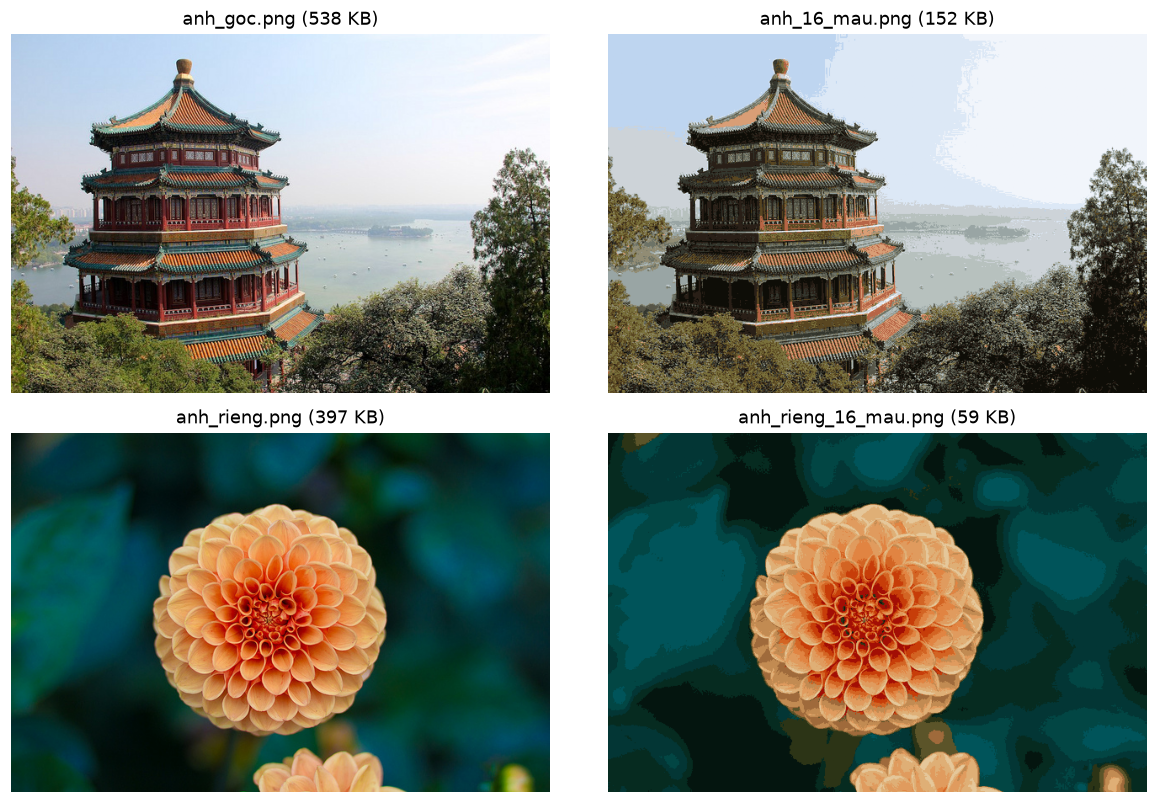

In [18]:
# Bốn tệp ảnh bài 4 vừa lưu
fig, axs = plt.subplots(2, 2, figsize=(11, 7.4))
for ax, ten in zip(axs.ravel(), ["anh_goc.png", "anh_16_mau.png", "anh_rieng.png", "anh_rieng_16_mau.png"]):
    ax.imshow(plt.imread(ten)); ax.set_title(f"{ten} ({os.path.getsize(ten) / 1024:.0f} KB)"); ax.axis("off")
plt.tight_layout(); plt.show()

**Nhận xét.** `anh_moi` có dạng (427, 640, 3), giá trị 0..1, nên `plt.imsave` lưu thẳng được. Sai lệch trung bình 7.97 mức sáng, đúng như mục 5.

| Tệp | Dung lượng |
|---|---|
| `anh_goc.png` | 538.4 KB |
| `anh_16_mau.png` | 151.8 KB, nhỏ hơn **3.5 lần** |

Tệp thật chỉ nhỏ hơn 3.5 lần chứ không phải 6 lần như phép tính 24/4 bit. `plt.imsave` vẫn ghi mỗi điểm đủ 4 kênh 8 bit (RGBA), không ghi kiểu "bảng 16 màu + số thứ tự 4 bit". Tệp nhỏ hơn là nhờ bộ nén của PNG: ảnh chỉ có 16 màu lặp lại thành những mảng giống nhau, nén tốt hơn nhiều so với ảnh gốc 96 615 màu. Muốn được đúng tỷ lệ 6 lần phải lưu ở dạng ảnh bảng màu (ví dụ PNG chế độ "P" của thư viện Pillow).

**Làm lại với ảnh khác.** Tôi không đưa ảnh cá nhân vào kho bài, nên dùng ảnh `flower.jpg` của scikit-learn, lưu trước thành `anh_rieng.png` để đóng vai một ảnh PNG đọc bằng `plt.imread`. Đọc vào được mảng **(427, 640, 4)** kiểu `float32` giá trị 0..1: có **kênh thứ tư là độ trong suốt** (toàn bằng 1.0). Phải bỏ kênh đó (`rieng[:, :, :3]`) trước khi phân cụm, nếu không mỗi điểm ảnh là một điểm bốn chiều và K-Means tính cả độ trong suốt vào khoảng cách; `reshape(-1, 3)` cũng sẽ cắt sai. Ảnh JPG đọc bằng `plt.imread` lại cho kiểu `uint8` giá trị 0..255, nên mã chia cho 255 trong trường hợp đó. Ảnh hoa 16 màu lệch 6.22 mức sáng và tệp nhỏ hơn 6.7 lần (396.5 KB xuống 59.3 KB). Tỷ lệ nén của tệp PNG phụ thuộc vào nội dung ảnh, không chỉ vào số màu.

## Bài tập 5: DBSCAN trên hai vầng trăng
`DBSCAN(eps=e, min_samples=5)` với e = 0.2, 0.3, 0.4; đếm số cụm và số điểm nhiễu (nhãn −1). Có giá trị nào tách hai vầng trăng tốt hơn K-Means? Vai trò của eps?

In [19]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons

tr = pd.read_csv("data/hai_vang_trang.csv")
X = tr[["x1", "x2"]].to_numpy()
y = tr["nhan"].to_numpy()


def ty_le_khop(nhan_cum, y=y):
    """Moi cum doan theo nhan that chiem da so; diem nhieu (-1) tinh la sai."""
    dung = 0
    for c in np.unique(nhan_cum):
        if c == -1:
            continue
        dung += np.bincount(y[nhan_cum == c]).max()
    return dung / len(y)


km = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
print(f"K-Means K = 2: ty le khop {ty_le_khop(km):.4f}")
print()

def bang_dbscan(X, y, cac_eps):
    print(" eps    so cum   so diem nhieu   ty le khop   co cau cum")
    for e in cac_eps:
        nhan = DBSCAN(eps=e, min_samples=5).fit_predict(X)
        so_cum = len(set(nhan)) - (1 if -1 in nhan else 0)
        nhieu = int((nhan == -1).sum())
        co_cau = np.bincount(nhan[nhan >= 0]).tolist() if so_cum else []
        print(f" {e:.2f}   {so_cum:6d}   {nhieu:13d}   {ty_le_khop(nhan, y):10.4f}   {co_cau}")
    print()


print("Bo hai vang trang cua bai 4, ba gia tri eps cua de:")
bang_dbscan(X, y, [0.2, 0.3, 0.4])
print("Do them eps nho hon:")
bang_dbscan(X, y, [0.10, 0.12, 0.15, 0.18])

# Khoảng cách tới láng giềng thứ 5 của mỗi điểm: gợi ý chọn eps
kc = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
kc5 = np.sort(kc, axis=1)[:, 5]                  # cột 0 là chính nó
print("Khoang cach toi lang gieng thu 5:")
print(f"  trung vi {np.median(kc5):.3f}, phan vi 90% {np.quantile(kc5, 0.9):.3f},"
      f" lon nhat {kc5.max():.3f}")
print()

# Cùng thí nghiệm trên hai vầng trăng ít nhiễu: giữa hai vầng có khe hở rõ
X_it, y_it = make_moons(n_samples=300, noise=0.05, random_state=0)
km_it = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_it)
print(f"Hai vang trang it nhieu (noise=0.05): K-Means khop {ty_le_khop(km_it, y_it):.4f}")
bang_dbscan(X_it, y_it, [0.2, 0.3, 0.4])

K-Means K = 2: ty le khop 0.7500

Bo hai vang trang cua bai 4, ba gia tri eps cua de:
 eps    so cum   so diem nhieu   ty le khop   co cau cum
 0.20        1              40       0.4367   [260]
 0.30        1              10       0.4933   [290]
 0.40        1               3       0.4967   [297]

Do them eps nho hon:
 eps    so cum   so diem nhieu   ty le khop   co cau cum
 0.10        6             257       0.1233   [9, 12, 5, 7, 5, 5]
 0.12       12             188       0.3200   [15, 12, 16, 20, 9, 5, 6, 7, 5, 5, 5, 7]
 0.15       16              99       0.5800   [28, 46, 26, 3, 8, 21, 12, 10, 6, 7, 6, 7, 5, 7, 4, 5]
 0.18        5              50       0.5767   [167, 7, 56, 8, 12]

Khoang cach toi lang gieng thu 5:
  trung vi 0.176, phan vi 90% 0.301, lon nhat 0.696

Hai vang trang it nhieu (noise=0.05): K-Means khop 0.7467
 eps    so cum   so diem nhieu   ty le khop   co cau cum
 0.20        2               0       1.0000   [150, 150]
 0.30        2               0       1.000

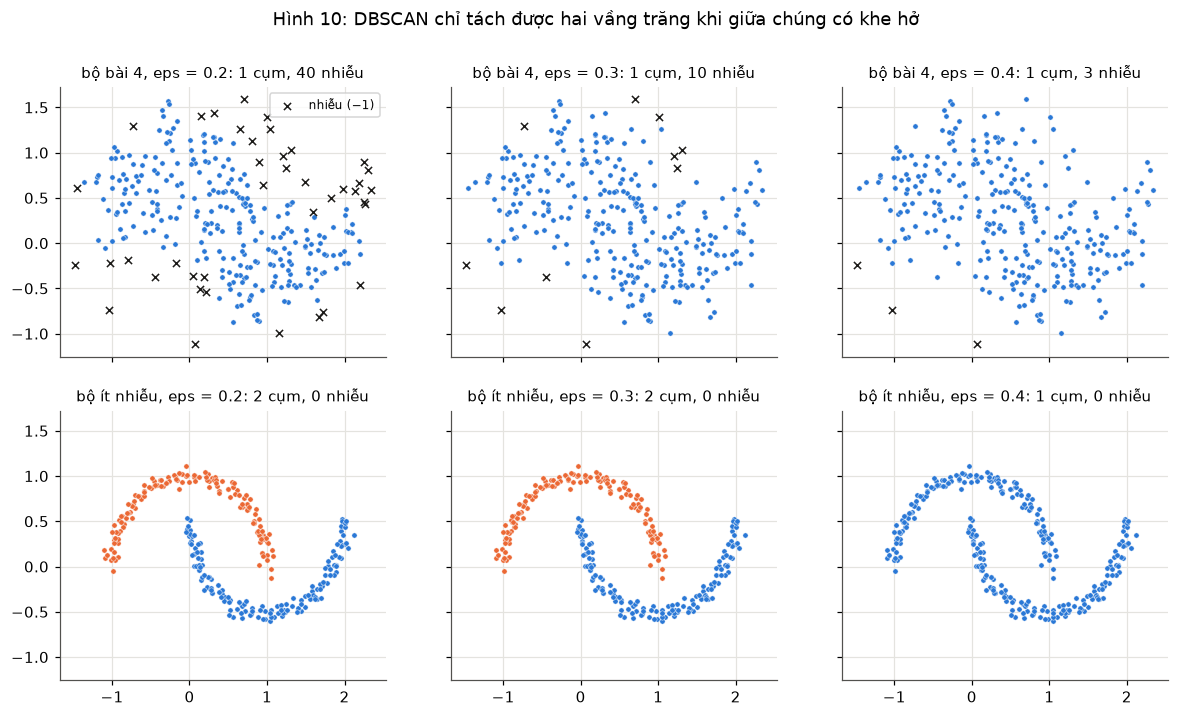

In [20]:
# Hình 10: DBSCAN với ba giá trị eps, hàng trên là bộ của bài 4, hàng dưới là bộ ít nhiễu
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for hang, (XX, ten_bo) in enumerate([(X, "bộ bài 4"), (X_it, "bộ ít nhiễu")]):
    for ax, e in zip(axs[hang], [0.2, 0.3, 0.4]):
        n_db = DBSCAN(eps=e, min_samples=5).fit_predict(XX)
        nhieu = n_db == -1
        for c in np.unique(n_db[~nhieu]):
            ax.scatter(XX[n_db == c, 0], XX[n_db == c, 1], s=12, c=MAU_CUM[c % 5], edgecolor="white", linewidth=0.3)
        ax.scatter(XX[nhieu, 0], XX[nhieu, 1], s=22, marker="x", c=MAU_TAM, linewidth=1, label="nhiễu (−1)")
        so_cum = len(set(n_db)) - (1 if nhieu.any() else 0)
        ax.set_title(f"{ten_bo}, eps = {e}: {so_cum} cụm, {nhieu.sum()} nhiễu", fontsize=10)
axs[0, 0].legend(fontsize=8)
fig.suptitle("Hình 10: DBSCAN chỉ tách được hai vầng trăng khi giữa chúng có khe hở"); plt.show()

**Nhận xét.** Trên bộ hai vầng trăng của bài 4, **không giá trị eps nào của đề tách được hai vầng trăng**, cả ba đều kém K-Means (0.7500):

| eps | số cụm | số điểm nhiễu | tỷ lệ khớp |
|---|---|---|---|
| 0.2 | 1 | 40 | 0.4367 |
| 0.3 | 1 | 10 | 0.4933 |
| 0.4 | 1 | 3 | 0.4967 |

(Tỷ lệ khớp: mỗi cụm đoán theo nhãn chiếm đa số trong cụm, điểm nhiễu tính là sai.) Lý do nằm ở dữ liệu: bộ này nhiễu nhiều, hai vầng trăng chồng lên nhau ở hai đầu (Hình 7 trái), không có khe hở mật độ thấp nào giữa chúng. DBSCAN nối hai điểm lõi nếu chúng cách nhau không quá eps, nên chỉ cần một chuỗi điểm dày nối hai vầng là cả hai thành một cụm. Dò thêm eps nhỏ hơn cũng không cứu được: eps = 0.15 cho 16 cụm vụn và 99 điểm nhiễu, eps = 0.10 biến 257/300 điểm thành nhiễu. Khoảng cách tới láng giềng thứ 5 có trung vị 0.176, tức với eps nhỏ hơn mức đó một nửa số điểm không còn là điểm lõi.

Trên hai vầng trăng **ít nhiễu** (`make_moons(noise=0.05)`, hàng dưới Hình 10), DBSCAN làm được việc K-Means không làm được: eps = 0.2 và 0.3 cho đúng **2 cụm, 0 nhiễu, khớp 1.0000**, trong khi K-Means vẫn chỉ 0.7467 vì ranh giới của nó luôn là đường thẳng.

**Vai trò của eps:** eps là bán kính "hàng xóm". eps quá nhỏ thì vùng thưa không đủ min_samples hàng xóm, nhiều điểm thành nhiễu và cụm vỡ vụn; eps quá lớn thì cầu nối giữa các cụm đủ dày, mọi thứ dính thành một cụm (eps = 0.4 ở bộ ít nhiễu). eps tốt phải lớn hơn khoảng cách giữa các điểm trong một cụm nhưng nhỏ hơn khe hở giữa hai cụm, và chỉ tồn tại khi khe hở đó có thật. Khác K-Means, DBSCAN không cần biết trước số cụm, đi được theo hình cong và tự đánh dấu điểm nhiễu; đổi lại nó rất nhạy với eps.

## Bài tập 6: Phân cụm chữ số viết tay
K-Means với K = 10 trên `load_digits`, không dùng nhãn; sau đó lập `pd.crosstab(nhan_that, cum)`. Chữ số nào được gom gọn vào một cụm? Những chữ số nào hay bị gom chung?

In [21]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits

so = load_digits()
X, nhan_that = so.data, so.target
print("Kich thuoc:", X.shape, "(moi anh 8 x 8 = 64 diem anh, gia tri 0..16)")
print()

# Các cột cùng thang 0..16 nên không cần chuẩn hoá
km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(X)
cum = km.labels_

bang = pd.crosstab(nhan_that, cum, rownames=["chu_so"], colnames=["cum"])
print(bang.to_string())
print()

# Mỗi cụm gọi theo chữ số chiếm đa số trong cụm
print("Cum   so mau   chu so chiem da so   ty le")
ten_cum = {}
for c in range(10):
    cot = bang[c]
    ten_cum[c] = cot.idxmax()
    print(f"  {c}     {cot.sum():4d}          {cot.idxmax()}            "
          f"{cot.max() / cot.sum():.2f}")
print()

# Với mỗi chữ số: tỷ lệ nằm trong cụm lớn nhất của nó
print("Chu so   cum chua nhieu nhat   ty le gom gon")
for d in range(10):
    hang = bang.loc[d]
    print(f"   {d}            {hang.idxmax()}               {hang.max() / hang.sum():.2f}")
print()

du_doan = np.array([ten_cum[c] for c in cum])
print(f"Gan moi cum bang chu so da so: dung {(du_doan == nhan_that).mean():.4f}")
thieu = sorted(set(range(10)) - set(ten_cum.values()))
print("Chu so khong lam da so o cum nao:", thieu)

Kich thuoc: (1797, 64) (moi anh 8 x 8 = 64 diem anh, gia tri 0..16)



cum       0    1    2   3    4    5    6    7    8    9
chu_so                                                 
0       176    0    0   0    0    0    2    0    0    0
1         0  100    0  54    1    2    0    1    0   24
2         1    8    3   2   13    0    0    0    2  148
3         0    7    7   0  154    0    0    2   13    0
4         0    2   11   3    0    0  165    0    0    0
5         0    0    0   0    2    1    2  136   41    0
6         1    3    0   0    0  177    0    0    0    0
7         0    2  174   2    0    0    0    1    0    0
8         0  100    5   6    2    2    0    4   52    3
9         0    1    8  20    6    0    0    6  139    0

Cum   so mau   chu so chiem da so   ty le
  0      178          0            0.99
  1      223          1            0.45
  2      208          7            0.84
  3       87          1            0.62
  4      178          3            0.87
  5      182          6            0.97
  6      169          4            0.98
  7  

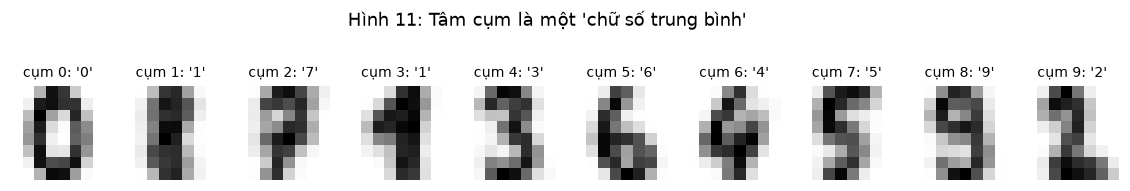

In [22]:
# Hình 11: mười tâm cụm vẽ lại thành ảnh 8 x 8, kèm chữ số chiếm đa số
fig, axs = plt.subplots(1, 10, figsize=(13, 1.9))
for c, ax in enumerate(axs):
    ax.imshow(km.cluster_centers_[c].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"cụm {c}: '{ten_cum[c]}'", fontsize=9); ax.axis("off")
fig.suptitle("Hình 11: Tâm cụm là một 'chữ số trung bình'", y=1.08); plt.show()

**Nhận xét.** 1797 ảnh 8 × 8 = 64 cột, mọi cột cùng thang 0..16 nên không chuẩn hoá. K-Means chạy hoàn toàn không dùng nhãn; bảng chéo lập sau mới cho thấy mỗi cụm chứa chữ số nào.

**Được gom gọn vào một cụm:** chữ số **0** (176/178 vào cụm 0, tỷ lệ 0.99), **6** (177/181, 0.98), **7** (174/179, 0.97) và **4** (165/181, 0.91). Các cụm đó cũng gần như thuần: cụm 0 có 99% là số 0, cụm 5 có 97% là số 6. Đây là những chữ số có hình dạng riêng: số 0 là vòng tròn kín, số 6 có vòng dưới, số 7 có nét ngang trên và không có nét dưới.

**Hay bị gom chung:**
- **1 và 8**: cụm 1 có đúng 100 số 1 và 100 số 8. Số 8 không làm đa số ở cụm nào, nên khi gán mỗi cụm theo chữ số chiếm đa số thì **không cụm nào mang tên 8**. Ngoài ra số 1 còn rải sang cụm 3 (54 ảnh) và cụm 9 (24 ảnh, chung với số 2): người viết số 1 theo nhiều kiểu (một nét, có mũ, có chân).
- **9, 8 và 5**: cụm 8 có 139 số 9, 52 số 8 và 41 số 5. Ba chữ số này cùng có vòng trên và nét cong dưới, trên lưới 8 × 8 rất dễ lẫn.
- **3** phần lớn vào cụm 4 (154/183), nhưng 13 ảnh rơi sang cụm 8 cùng nhóm 9, 8, 5.

Nếu gán mỗi cụm bằng chữ số chiếm đa số, tỷ lệ đúng là **0.7919**, khá cao cho một thuật toán không hề nhìn nhãn. Hình 11 vẽ lại từng tâm cụm thành ảnh: tâm là "chữ số trung bình" của cụm, nhìn ra rõ 0, 6, 7, 4, 3, 2, còn tâm cụm 1 (lẫn 1 và 8) và cụm 8 (lẫn 9, 8, 5) bị nhoè. Nhưng K-Means chỉ đo khoảng cách theo từng điểm ảnh: hai cách viết số 1 lệch nhau vài điểm ảnh thì xa nhau, còn số 8 mảnh và số 1 đậm lại có thể gần nhau. Cụm của K-Means là cụm theo hình dạng điểm ảnh, không phải theo ý nghĩa chữ số.